# Práctica 3
Daniela Andrea Torres Gómez
## PARTE 1: COMPARACIÓN DE OPTIMIZADORES


Esta parte tiene como objetivo evaluar y comparar el rendimiento de cuatro algoritmos de optimización fundamentales —Gradiente Descendente (GD), Optimización por Colonia de Hormigas (ACO), Optimización por Enjambre de Partículas (PSO) y Algoritmos Genéticos (GA)— utilizando la función de Rosenbrock como entorno de prueba.
La función de Rosenbrock se define matemáticamente como: 

$\begin{equation} 𝑓(𝑥,𝑦)=(𝑎−𝑥)^2+𝑏(𝑦−𝑥^2)^2 \end{equation}$

Para este análisis comparativo, utilizaremos los parámetros estándar de la industria:

$
𝑎=1
$

$
𝑏=100
$

lo que sitúa el mínimo global en el punto $(1,1)$ con un valor óptimo de $𝑓(1,1)=0$.

El Reto de la Función de Rosenbrock: La topografía de esta función simula un valle parabólico largo, estrecho y de pendiente muy suave. Aunque encontrar el valle es una tarea sencilla para la mayoría de los métodos, avanzar por su fondo plano hacia el mínimo global exacto representa un desafío crítico.
El gradiente para esta función es:

El gradiente para esta función es: 

$
\begin{equation}
\begin{bmatrix}
\frac{df}{dx} \\
\frac{df}{dy} 
\end{bmatrix} = 
\begin{bmatrix}
-2(a-x) - 4bx(y-x^2) \\
2b(y-x^2)
\end{bmatrix}
\end{equation}
$

Para la ejecución de los algoritmos tenga en cuenta:
 - Definir puntos de partida aleatorios en el rango de $𝑥∈[−2,2]$ y $𝑦∈[−1,3]$
 - Calcule la precisión final: qué tan cerca quedó el algoritmo del punto $(1,1)$
 - Velocidad de convergencia: para GA, PSO y ACO, a partir de la gráfica de convergencia, determine en qué momento se estabiliza el resultado. ¿Qué algoritmo converge más rápido?



In [4]:
import numpy as np 
import matplotlib.pyplot as plt

Se grafica la Función de Rosenbrock

In [8]:
#Minimizacion de una funcion 2D
a = 1
b = 100
f = lambda x, y: (a - x)**2 + b*(y - x**2)**2
def objective_func(solution):
    x = solution[0]
    y = solution[1]
    f = (a - x)**2 + b*(y - x**2)**2
    return f

In [9]:
def plot(funcion, xy_lim, step, solution = []):
    y = np.arange(xy_lim[0], xy_lim[1], step)
    x = np.arange(xy_lim[0], xy_lim[1], step)
    X, Y = np.meshgrid(x, y)
    Z = funcion(X, Y)
    print('Z shape:' ,Z.shape)
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    # 2. Convertimos el PRIMER eje a 3D usando fig.add_subplot de forma correcta (1 fila, 2 columnas, posición 1)
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    surf = ax1.plot_surface(X, Y, Z, cmap='jet')
    ax1.set_title('Superficie 3D')

    # 3. El SEGUNDO eje se queda en 2D por defecto
    # Usamos las coordenadas originales x, y para el mapa de contornos plano
    contour = ax2.contourf(x, y, Z, levels=50, cmap='jet')
    ax2.scatter(1, 1, c='pink', marker='o', s=100, edgecolors='black', zorder=5)
    ax2.text(1.5, 1, '(1,1)', color='pink', va='center')
    # Validamos si se ingresó una solución y si no está vacía (compatible con listas y arrays de NumPy)
    if solution is not None and np.size(solution) > 0:
        ax2.scatter(solution[0], solution[1], c='white', marker='o', s=100, edgecolors='black', zorder=5)
        
        
    ax2.set_title('Mapa de Contorno 2D')
    ax2.set_xlabel('Eje X')
    ax2.set_ylabel('Eje Y')

    # 4. Añadimos la barra de color asignada al gráfico de contorno plano
    fig.colorbar(contour, ax=ax2, shrink=0.8)

    # Ajusta el espacio para que no se encimen los títulos
    plt.tight_layout()
    plt.show()

Z shape: (200, 200)


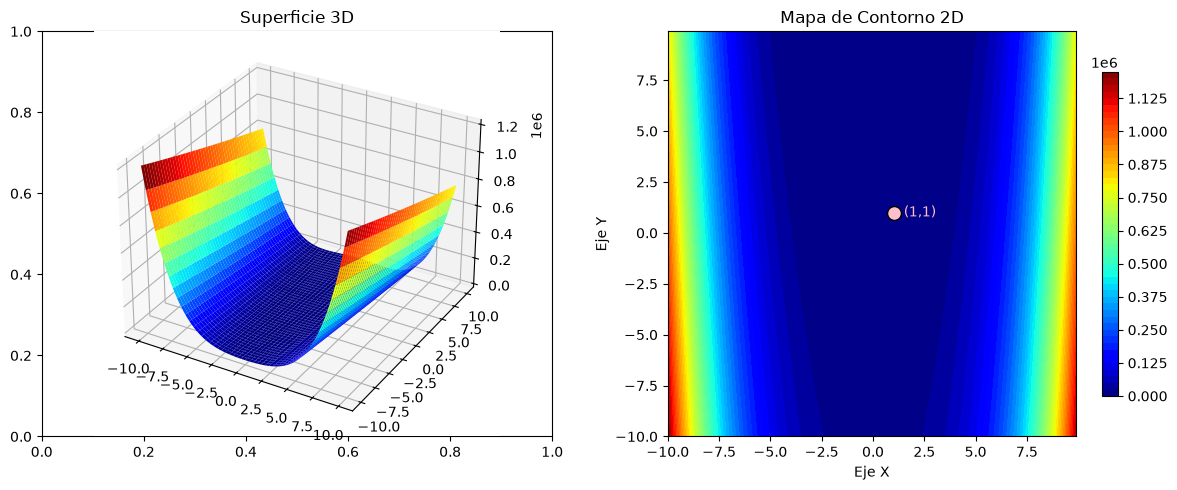

In [11]:
plot(f, xy_lim=(-10, 10), step=0.1)

### Gradiente Descendente (GD)

In [12]:
#Funcion del gradiente descendente
def gradient_descent(objective_func, derivative, bounds, n_iter, step_size):
  # Generamos el punto inicial de forma aleatoria
  solution = bounds[:,0] + np.random.rand(len(bounds))*(bounds[:,1]-bounds[:,0])
	# Algoritmo iterativo
  for i in range(n_iter):
		#1. Calculo del gradiente
    gradiente = derivative(solution)
		#2. Actualizacion de la solucion
    solution = solution - step_size*gradiente
  	#3. Evaluacion de la solucion
    solution_eval = objective_func(solution)
    #print('>%d f(%s) = %.5f' % (i, solution, solution_eval))
  return solution

El gradiente para esta función es: 

$
\begin{equation}
\begin{bmatrix}
\frac{df}{dx} \\
\frac{df}{dy} 
\end{bmatrix} = 
\begin{bmatrix}
-2(a-x) - 4bx(y-x^2) \\
2b(y-x^2)
\end{bmatrix}
\end{equation}
$

Para la ejecución de los algoritmos tenga en cuenta:
 - Definir puntos de partida aleatorios en el rango de $𝑥∈[−2,2]$ y $𝑦∈[−1,3]$
 - Calcule la precisión final: qué tan cerca quedó el algoritmo del punto $(1,1)$

In [13]:
#Funcion que evalua el gradiente en un punto solucion
def derivative(X):
  x = X[0]
  y = X[1]
  term0 = -2*(a - x) - 4*b*x*(y - x**2)
  term1 = 2*b*(y - x**2)
  gradiente = np.array([term0,term1])
  return gradiente

In [14]:
# Deliminatos el rango de los datos
bounds = np.asarray([[-2.0, 2.0], [-1.0, 3.0]])
# Definimos el numero de iteraciones
n_iter = 200
# Seleccionamos la longitud del paso
step_size = 0.0001
# Aplicamos el algoritmo de gradiente descendente
solution_GD = gradient_descent(objective_func, derivative, bounds, n_iter, step_size)
solution_GD

array([0.60446799, 0.36358472])

fevalGD: 0.15676842974258914, solucion: [0.60446799 0.36358472]
Z shape: (200, 200)


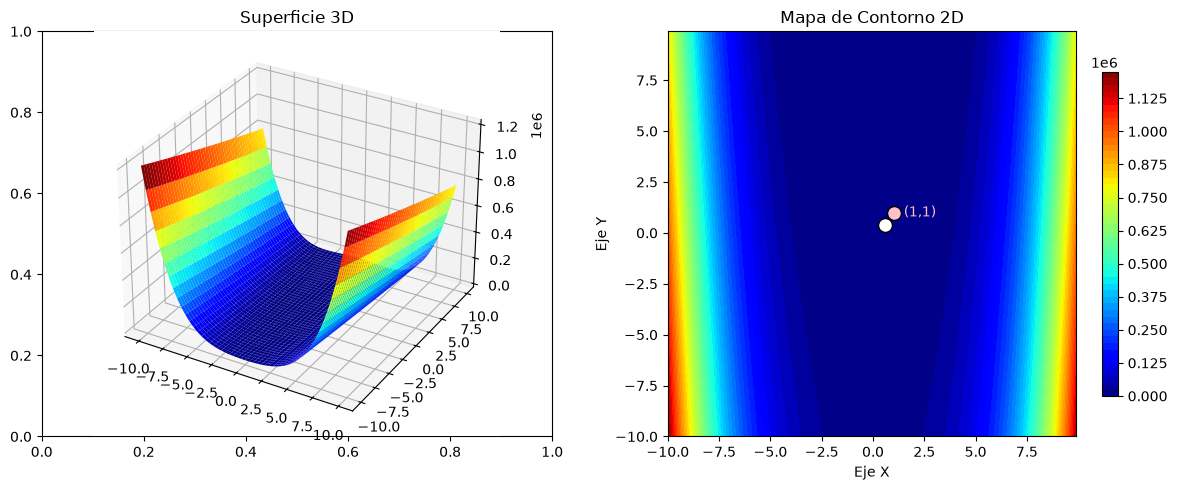

In [15]:
fevalGD = objective_func(solution_GD)
print(f'fevalGD: {fevalGD}, solucion: {solution_GD}')

plot(f, xy_lim=(-10, 10), step=0.1, solution=solution_GD)

### Algoritmos Genéticos (GA)

In [210]:
import pygad

In [211]:
def fitness_func(ga_instance, solution, solution_idx):
    #Llamamos nuestra funcion objetivo
    
    output = objective_func(solution)

    #Calculamos el fitness (Convertimos el problema de minimizacion a maximizacion)

    fitness = 1.0 / (1.0 + output)
    return fitness

In [212]:
# Configuracion del espacio de busqueda
# Definimos el tipo de dato y las restricciones para cada gen individualmente

gene_space = [
    {'low': 10, 'high': 300, 'step': 1},        # n_estimators
    {'low': 3, 'high': 30, 'step': 1},         # max_depth
]

#Dimension del gen: 2 en este caso, 2 genes 
num_genes = len(gene_space)

In [213]:
#Paso 2: Preparamos los parametros para correr el algoritmo genetico e instanciamos el modelo
ga_instance = pygad.GA(
                       num_generations= 200, #Numero de generaciones
                       num_parents_mating = 6, #Numero de soluciones a ser seleccionadas como padres
                       fitness_func = fitness_func, #Establecer la funcion fitness
                       sol_per_pop = 20,#Numero de soluciones por poblacion
                       num_genes = 2, #Numero de genes en la solucion
                       init_range_low=-4, #Rangos iniciales para la poblacion inicial
                       init_range_high=4,
                       #Metodo para la seleccion de padres, #"rws": Ruleta,#"tournament": Torneo
                       parent_selection_type='tournament',
                       keep_parents=3, #Numero de padres a mantener en la poblacion
                       crossover_type= 'single_point', #Tipo de cruce: en un solo punto, dos puntos, uniforme
                       crossover_probability = 0.5, #Probabilidad para realizar el cruze
                       mutation_type= 'random', #Tipo de mutacion
                       mutation_probability=0.1 #Probabilidad de mutacion
                       ) 

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\pygad\utils\validation.py:459: UserWarning: keep_elitism (=1) takes precedence over keep_parents (=3). Set keep_elitism=0 to retain parents instead.
  warnings.warn(f'keep_elitism (={self.keep_elitism}) takes precedence over keep_parents (={self.keep_parents}). Set keep_elitism=0 to retain parents instead.')


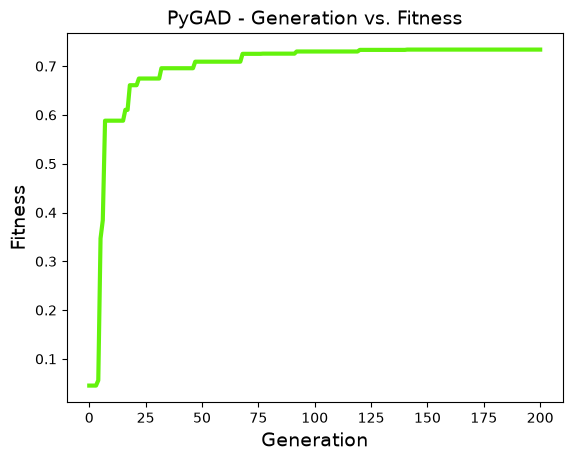

In [214]:
#Corremos el algoritmo
ga_instance.run()

#Grafica de fitness
ga = ga_instance.plot_fitness()

In [215]:
#Extraemos la mejor solucion
solution_ga, solution_fitness_ga, solution_idx_ga = ga_instance.best_solution()
print(f"Parameters of the best solution : {solution_ga}")
print(f"Fitness value of the best solution = {solution_fitness_ga}")

Parameters of the best solution : [0.398202   0.15663263]
Fitness value of the best solution = 0.7339265481716936


feval algoritmo genetico: 3.2542441960990134, solucion: [0.398202   0.15663263]
Z shape: (200, 200)


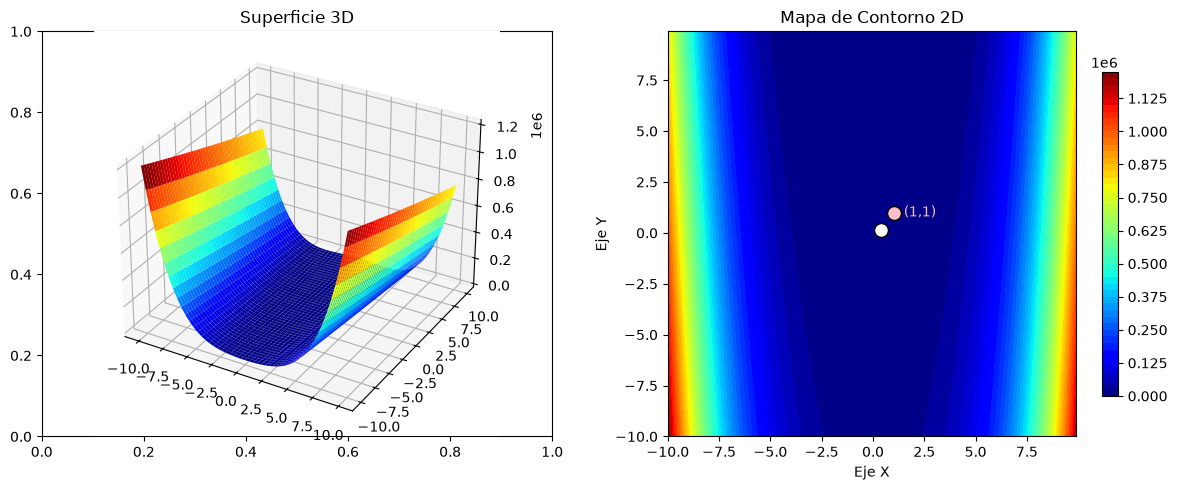

In [216]:
feval_GA = objective_func(solution_ga)
print(f'feval algoritmo genetico: {fevalAG}, solucion: {solution_ga}')

plot(f, xy_lim=(-10, 10), step=0.1, solution=solution_ga)

### Optimización por Colonia de Hormigas (ACO)



In [217]:
#Importar libreria
import pymetaheuristic

In [218]:
# Optimize - Run
aco_instance = pymetaheuristic.optimize(
                                  algorithm                  = "acor", # funciones continuas 
                                  target_function            = objective_func,
                                  min_values                 = (-4, -4),
                                  max_values                 = ( 4,  4),
                                  max_steps                  = 25, # iterations
                                  store_history              = True,
                                  store_population_snapshots = True,
                                  population_size            = 30 #Tamaño de la población
                                )

c:\Users\50649\.conda\envs\ia_opt\Lib\site-packages\pymetaheuristic\src\engines\_ported_common.py:153: UserWarning: [acor] Source task-level repair/history is mapped to ProblemSpec evaluation; source task history is not tracked.
  self._warn_once(


In [219]:
#Grafica de convergencia
fig = pymetaheuristic.plot_convergence(aco_instance, show = True, x_axis = "steps", renderer = 'colab')

Parameters of the best solution ACO: [0.7787272693013829, 0.6068475243897661]
Fitness value of the best solution = 0.04898022887850259
feval algoritmo genetico: 0.04898022887850259, solucion: [0.7787272693013829, 0.6068475243897661]
Z shape: (200, 200)


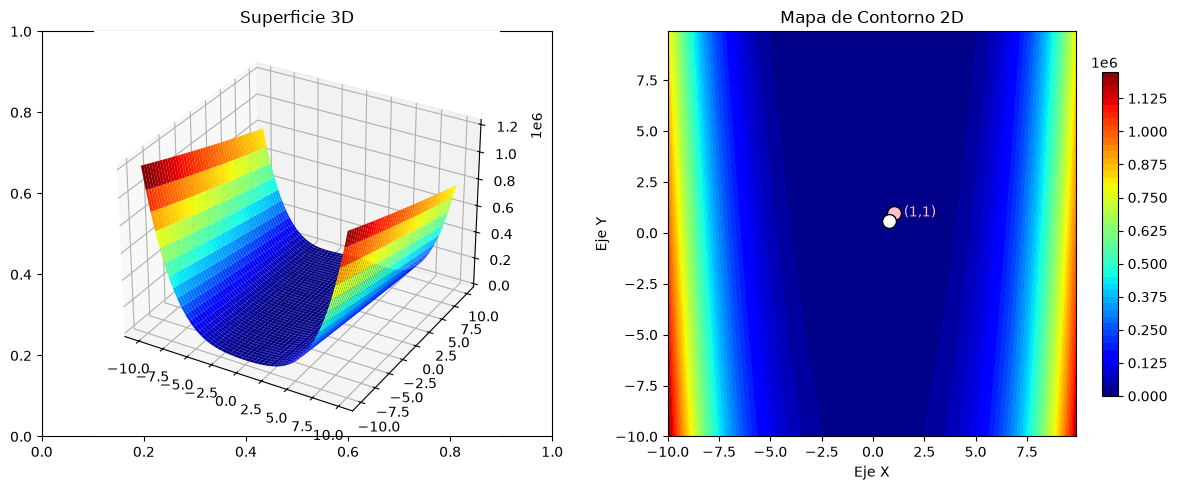

In [220]:
#Extraemos la mejor solucion
solution_aco = aco_instance.best_position
solution_aco_fitness =  aco_instance.best_fitness
print(f"Parameters of the best solution ACO: {solution_aco}")
print(f"Fitness value of the best solution = {solution_aco_fitness}")

feval_aco = objective_func(solution_aco)
print(f'feval algoritmo genetico: {feval_aco}, solucion: {solution_aco}')

plot(f, xy_lim=(-10, 10), step=0.1, solution=solution_aco)

### Optimización por Enjambre de Partículas (PSO) 

In [221]:
# Optimize - Run
pso_instance = pymetaheuristic.optimize(
                                  algorithm                  = 'pso', # 'pso' or 'aco'
                                  target_function            = objective_func,
                                  min_values                 = (-4,-4),
                                  max_values                 = (4,4),
                                  max_steps                  = 200, # iterations
                                  store_history              = True,
                                  store_population_snapshots = True,
                                  swarm_size                 = 30, #Numero de particulas
                                  w                          = 0.9, #Inercia 90% de inercia
                                  c1                         = 2, #Coeficiente cognitivo: 2 valor recomendado
                                  c2                         = 2 #Coeficiente social: 2 valor recomendado, igual al cognitivo 
)

In [222]:
#Grafica de convergencia
fig = pymetaheuristic.plot_convergence(pso_instance, show = True, x_axis = "steps", renderer = 'colab')

Parameters of the best solution pso: [1.1334916725762092, 1.2795403564900911]
Fitness value of the best solution = 0.020589959662019087
feval algoritmo genetico: 0.020589959662019087, solucion: [1.1334916725762092, 1.2795403564900911]
Z shape: (200, 200)


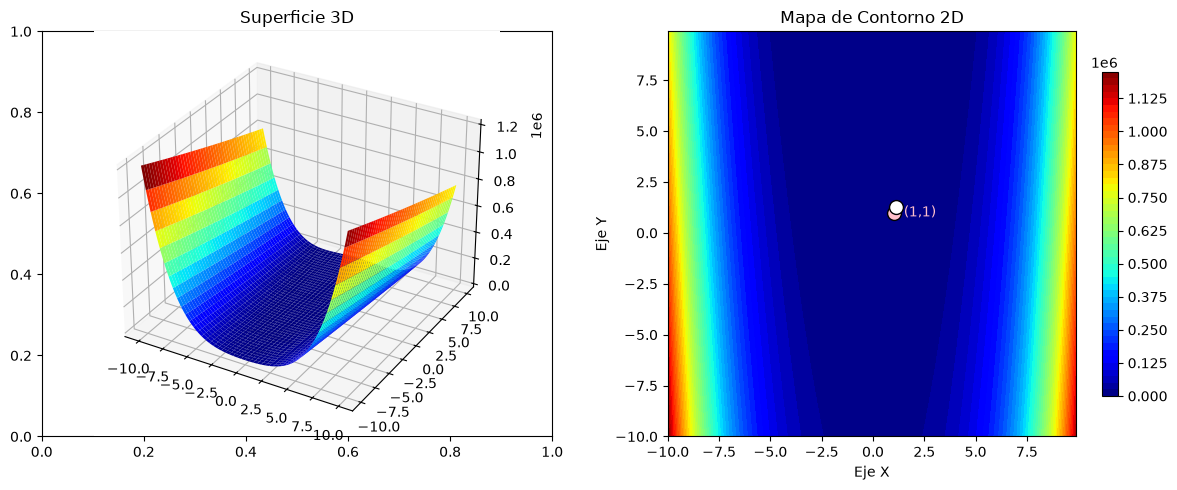

In [223]:
#Extraemos la mejor solucion
solution_pso = pso_instance.best_position
solution_pso_fitness =  pso_instance.best_fitness
print(f"Parameters of the best solution pso: {solution_pso}")
print(f"Fitness value of the best solution = {solution_pso_fitness}")

feval_pso = objective_func(solution_pso)
print(f'feval algoritmo genetico: {feval_pso}, solucion: {solution_pso}')

plot(f, xy_lim=(-10, 10), step=0.1, solution=solution_pso)

### Comparación

In [224]:
import pandas as pd

def comparar_multiples_metodos(metodos_resultados, f_real, x_real=None):
    """
    Compara de forma escalable N cantidad de métodos de optimización.
    
    Parámetros:
    - metodos_resultados: Diccionario { 'NombreMetodo': [lista de soluciones de cada ejecución] }
                          Cada solución debe ser un array/lista con las coordenadas [x, y].
    - f_real: El valor mínimo global teórico conocido.
    - x_real: (Opcional) Las coordenadas [x, y] del óptimo teórico para calcular distancia.
    """
    resumen_metricas = []
    
    for nombre_metodo, resultado in metodos_resultados.items():

        soluciones = resultado[0]
        f_calc = resultado[1]
        
        # 2. Calculamos el error único (Distancia absoluta al óptimo teórico)
        error_unico = abs(f_calc - f_real)
        
        # Guardamos un único registro por método
        resumen_metricas.append({
            "Método": nombre_metodo,
            "Valor f(x,y) Obtenido": f_calc,
            "Error Absoluto": error_unico,
            "X_sol": soluciones[0],
            "Y_sol": soluciones[1]
        })
    
    # Creamos la tabla y la ordenamos del menor error al mayor
    df_resultados = pd.DataFrame(resumen_metricas)
    return df_resultados.sort_values(by="Error Absoluto").reset_index(drop=True)


In [225]:
f_real_teorico = 0.0
x_real_teorico = [1.0, 1.0]

# 2. Empaquetamos todo en el diccionario escalable
datos_experimento = {
    "Gradiente Descendiente(GD)": [solution_GD, fevalGD],
    "Algoritmo genético (GA)": [solution_ga, fevalAG],
    "Colonia de Hormigas (ACO)": [solution_aco, feval_aco],
    "Enjambre de Partículas (PSO)": [solution_pso, feval_pso]  # <-- Agregar nuevos métodos es tan fácil como meter una línea aquí
}

# 4. Ejecutamos la comparación analítica
tabla_comparativa = comparar_multiples_metodos(
    metodos_resultados=datos_experimento,
    f_real=f_real_teorico,
    x_real=x_real_teorico
)

tabla_comparativa

,Método,"Valor f(x,y) Obtenido",Error Absoluto,X_sol,Y_sol
0,Enjambre de Partículas (PSO),0.020590,0.020590,1.133492,1.279540
1,Colonia de Hormigas (ACO),0.048980,0.048980,0.778727,0.606848
2,Gradiente Descendiente(GD),0.096163,0.096163,0.690248,0.474969
3,Algoritmo genético (GA),3.254244,3.254244,0.398202,0.156633
